In [9]:
import mindspore.dataset as ds

dataset_dir = "./dataset/MedNIST/"
dataset = ds.ImageFolderDataset(dataset_dir, decode=True)

In [10]:
import mindspore.dataset.vision as vision

# کلاسوں کے نام حاصل کرنا
class_names = dataset.get_class_indexing()
print("All classes:", class_names)

# نارملائزیشن کی ویلیوز
mean = [0.485 * 255, 0.456 * 255, 0.406 * 255]
std = [0.485 * 255, 0.456 * 255, 0.406 * 255]

trans = [
    vision.Resize((128, 128)),
    vision.Normalize(mean=mean, std=std),
    vision.HWC2CHW()
]

# ڈیٹا ٹرانسفارمیشن لاگو کرنا
dataset = dataset.map(operations=trans, input_columns="image")

# ڈیٹا سیٹ کو ٹرین اور ٹیسٹ میں تقسیم کرنا (80% Train, 20% Val)
ds_train, ds_val = dataset.split([0.8, 0.2], randomize=True)

# بیچنگ اور شفلنگ
ds_train = ds_train.shuffle(buffer_size=1000).batch(batch_size=32, drop_remainder=True)
ds_val = ds_val.batch(batch_size=32)

print("Training dataset size:", ds_train.get_dataset_size())
print("Test dataset size:", ds_val.get_dataset_size())

[WARNING] ME(13592:15008,MainProcess):2026-10-12-12:16:09.276.216 [mindspore\dataset\engine\datasets.py:1209] Dataset is shuffled before split.


All classes: {'AbdomenCT': 0, 'BreastMRI': 1, 'CXR': 2, 'ChestCT': 3, 'Hand': 4, 'HeadCT': 5}
Training dataset size: 1473
Test dataset size: 369


In [11]:
import mindspore.nn as nn

class MedicalNet(nn.Cell):
    def __init__(self, num_class, dropout_rate=0.5):
        super(MedicalNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, pad_mode='same')
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, pad_mode='same')
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, pad_mode='same')
        self.max_pool2d = nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Dense(64 * 16 * 16, 256)
        self.fc2 = nn.Dense(256, num_class)
        self.relu = nn.ReLU()
        # MindSpore میں عام طور پر p=dropout_rate یا keep_prob استعمال ہوتا ہے
        try:
            self.dropout = nn.Dropout(p=dropout_rate)
        except TypeError:
            self.dropout = nn.Dropout(keep_prob=1.0 - dropout_rate)

    def construct(self, x):
        x = self.max_pool2d(self.relu(self.conv1(x)))
        x = self.max_pool2d(self.relu(self.conv2(x)))
        x = self.max_pool2d(self.relu(self.conv3(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

net = MedicalNet(num_class=len(class_names))
print(net)

MedicalNet(
  (conv1): Conv2d(input_channels=3, output_channels=16, kernel_size=(3, 3), stride=(1, 1), pad_mode=same, padding=0, dilation=(1, 1), group=1, has_bias=False, weight_init=<mindspore.common.initializer.HeUniform object at 0x0000019903162220>, bias_init=None, format=NCHW)
  (conv2): Conv2d(input_channels=16, output_channels=32, kernel_size=(3, 3), stride=(1, 1), pad_mode=same, padding=0, dilation=(1, 1), group=1, has_bias=False, weight_init=<mindspore.common.initializer.HeUniform object at 0x0000019901CCD370>, bias_init=None, format=NCHW)
  (conv3): Conv2d(input_channels=32, output_channels=64, kernel_size=(3, 3), stride=(1, 1), pad_mode=same, padding=0, dilation=(1, 1), group=1, has_bias=False, weight_init=<mindspore.common.initializer.HeUniform object at 0x0000019901CCD8E0>, bias_init=None, format=NCHW)
  (max_pool2d): MaxPool2d(kernel_size=2, stride=2, pad_mode=VALID)
  (flatten): Flatten()
  (fc1): Dense(input_channels=16384, output_channels=256, has_bias=True)
  (fc2): D

In [12]:
import mindspore as ms
import mindspore.nn as nn

# لاس فنکشن، آپٹیمائزر اور ماڈل ڈیفائن کرنا
loss_fn = nn.CrossEntropyLoss()
optimizer = nn.Adam(net.trainable_params(), learning_rate=1e-4)

# metrics کو ڈکشنری فارمیٹ میں سیٹ کریں تاکہ درست طریقے سے مانیٹر ہو سکے
metrics = {
    'accuracy': nn.Accuracy(),
    'loss': nn.Loss()
}

model = ms.Model(net, loss_fn=loss_fn, optimizer=optimizer, metrics=metrics)

# ہائپر پیرامیٹرز
epochs = 3
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

print("ہائپر پیرامیٹرز اور ماڈل کامیابی سے تیار ہو گئے!")

ہائپر پیرامیٹرز اور ماڈل کامیابی سے تیار ہو گئے!


In [13]:
from mindspore.train import LossMonitor

print("Start training...")

for epoch in range(epochs):
    # ٹریننگ (1 epoch کے لیے)
    model.train(1, ds_train, callbacks=[LossMonitor(50)], dataset_sink_mode=False)
    
    # ایویلیوایشن
    train_metrics = model.eval(ds_train, dataset_sink_mode=False)
    val_metrics = model.eval(ds_val, dataset_sink_mode=False)
    
    # تاریخچہ محفوظ کرنا
    history["train_loss"].append(train_metrics['loss'])
    history["train_acc"].append(train_metrics['accuracy'])
    history["val_loss"].append(val_metrics['loss'])
    history["val_acc"].append(val_metrics['accuracy'])
    
    print(f"Epoch {epoch+1}/{epochs} -> "
          f"Train Acc: {train_metrics['accuracy']:.4f}, Val Acc: {val_metrics['accuracy']:.4f} | "
          f"Train Loss: {train_metrics['loss']:.4f}, Val Loss: {val_metrics['loss']:.4f}")

print("Training completed! ")

Start training...
epoch: 1 step: 50, loss is 0.5742629170417786
epoch: 1 step: 100, loss is 0.16892671585083008
epoch: 1 step: 150, loss is 0.08262156695127487
epoch: 1 step: 200, loss is 0.03191015124320984
epoch: 1 step: 250, loss is 0.12700526416301727
epoch: 1 step: 300, loss is 0.07193829119205475
epoch: 1 step: 350, loss is 0.021482184529304504
epoch: 1 step: 400, loss is 0.011518344283103943
epoch: 1 step: 450, loss is 0.022674567997455597
epoch: 1 step: 500, loss is 0.0735190212726593
epoch: 1 step: 550, loss is 0.011162683367729187
epoch: 1 step: 600, loss is 0.0038313716650009155
epoch: 1 step: 650, loss is 0.0037154555320739746
epoch: 1 step: 700, loss is 0.05802502483129501
epoch: 1 step: 750, loss is 0.04018770158290863
epoch: 1 step: 800, loss is 0.017143860459327698
epoch: 1 step: 850, loss is 0.0037068575620651245
epoch: 1 step: 900, loss is 0.025004416704177856
epoch: 1 step: 950, loss is 0.0005914419889450073
epoch: 1 step: 1000, loss is 0.0013712048530578613
epoch: 1

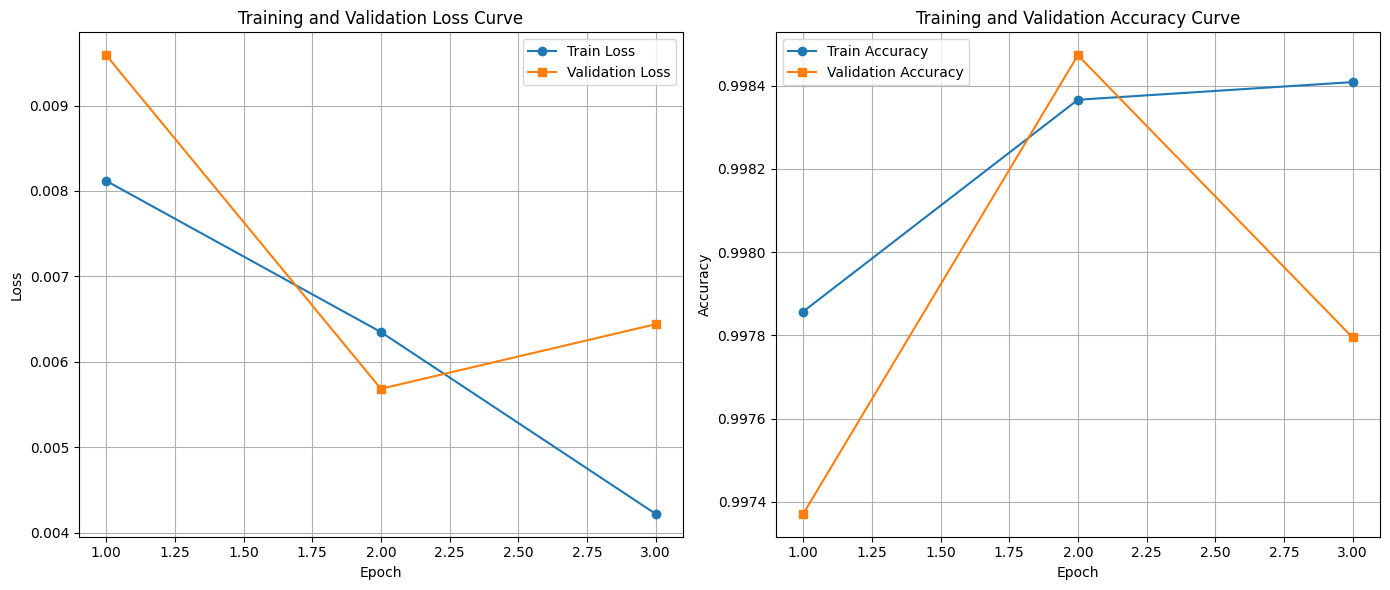

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# 1. Loss curve
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), history['train_loss'], marker='o', label='Train Loss')
plt.plot(range(1, epochs + 1), history['val_loss'], marker='s', label='Validation Loss')
plt.title('Training and Validation Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 2. Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), history['train_acc'], marker='o', label='Train Accuracy')
plt.plot(range(1, epochs + 1), history['val_acc'], marker='s', label='Validation Accuracy')
plt.title('Training and Validation Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

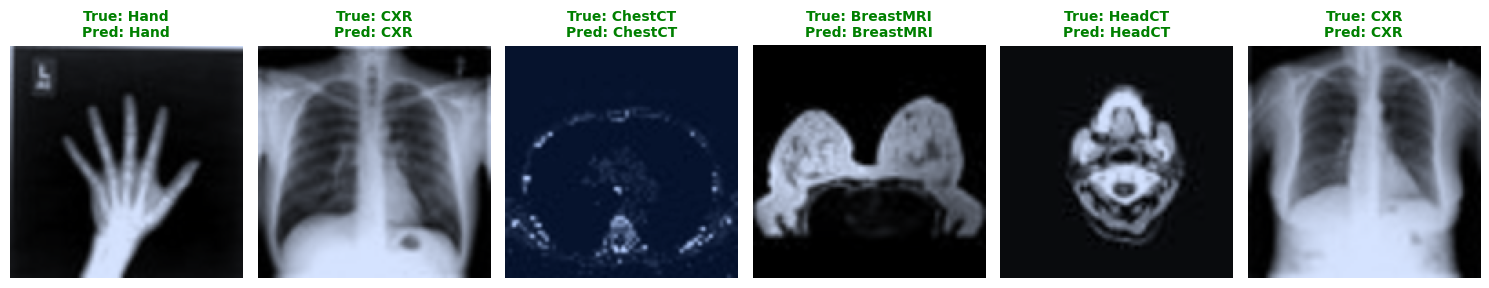

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import mindspore as ms

# ڈکشنری کو ریورس کرنا تاکہ نمبر (Index) سے کلاس کا نام مل سکے
idx_to_class = {v: k for k, v in class_names.items()}

# ٹیسٹ ڈیٹا سیٹ سے ایک بیچ حاصل کرنا
data_iter = next(ds_val.create_dict_iterator(output_numpy=True))
images = data_iter["image"]
labels = data_iter["label"]

# ماڈل کے ذریعے پریڈکشن کرنا
net.set_train(False)
output = net(ms.Tensor(images))
preds = np.argmax(output.asnumpy(), axis=1)

# تصاویر اور پریڈکشن ڈسپلے کرنا
plt.figure(figsize=(15, 5))
for i in range(min(6, len(images))):
    plt.subplot(1, 6, i + 1)
    
    # امیج فارمیٹ تبدیل کرنا (CHW سے HWC)
    img = images[i].transpose(1, 2, 0)
    
    # کلرز کو درست ڈسپلے رینج میں لانا
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    
    plt.imshow(img)
    
    # ریورس ڈکشنری سے نام حاصل کرنا
    true_label = idx_to_class[int(labels[i])]
    pred_label = idx_to_class[int(preds[i])]
    
    color = 'green' if true_label == pred_label else 'red'
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()